# Trabalho 2 — M2: baseline rodando
**Previsão de problemas respiratórios com base na qualidade do ar** · Redes Neurais e Aprendizado Profundo (EMA9824) · Grupo: Lucas Silveira, Nívea Batoni, Renan Cazelotto

**O que este notebook faz**
1. Lê os dados do `dados_t2.zip` (internações e qualidade do ar de Piracicaba e de São Paulo), mostra a cobertura de cada variável e decide quais entram.
2. Aplica **um único pré-processamento** a todos os modelos (mesma divisão, mesma métrica, como a proposta exige).
3. Mede os três baselines da seção 3 da proposta, em cada município e nos horizontes de 1, 7 e 14 dias:
   média sazonal com tendência · regressão de Poisson **sem** poluentes · regressão de Poisson **com** poluentes.
4. Gera a figura (curvas de treino e validação) e as tabelas de MAE e de tempos. O parágrafo do M2 já está escrito na seção 5.

**Regras do projeto que o notebook respeita**
- **O teste (2019) está bloqueado.** Os dados são cortados em 31/12/2018 logo na leitura; todas as métricas daqui são de **validação (2018)**. A leitura do teste fica para a entrega final (M3), uma única vez.
- Divisão pela data do **alvo**: treino 2014–2017, validação 2018. As entradas só usam dias ≤ origem *t*; o alvo é o dia *t + h*.
- Todo parâmetro estimado (médias de preenchimento, padronização, fatores sazonais, pesos) usa **somente o treino**.
- Os modelos de Poisson começam sempre dos mesmos pesos iniciais, então não dependem de semente.

**Como executar no Google Colab:** indique em `CAMINHO_ZIP` (seção 2) onde está o `dados_t2.zip`, em qualquer pasta, e use `Ambiente de execução → Executar tudo`. Se o caminho estiver no Drive, o Colab pede autorização na primeira vez; se o arquivo não for encontrado, o notebook oferece o upload manual. Não precisa de GPU.

In [ ]:
# ============================== 1. Configuração ==============================
import os, sys, glob, time, zipfile, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.easter import easter
from scipy.stats import poisson
from sklearn.linear_model import PoissonRegressor        # usado só na verificação de sanidade
from IPython.display import display

T0 = time.perf_counter()                                  # cronômetro (é reiniciado depois de obter os dados)
SEMENTE = 42
np.random.seed(SEMENTE)

# --- Divisão temporal (sempre pela data do ALVO) ---
FIM_TREINO = '2017-12-31'                                 # treino: 2014–2017
INI_VAL, FIM_VAL = '2018-01-01', '2018-12-31'             # validação: 2018
ULTIMO_DIA_USAVEL = FIM_VAL                               # M2: TESTE (2019) BLOQUEADO.
                                                          # No M3, trocar por '2019-12-31' e consultar o teste uma única vez.

HORIZONTES = [1, 7, 14]                                   # dias à frente
MUNICIPIOS = {                                            # município -> (arquivo de internações, arquivo de qualidade do ar)
    'Piracicaba': ('internacoes_respiratorias-Piracicaba.csv', 'diario_municipio_Piracicaba.csv'),
    'São Paulo':  ('internacoes_respiratorias-Sao_Paulo.csv',  'diario_municipio_Sao_Paulo.csv'),
}
POLUENTES = ['mp10', 'mp25', 'no2', 'o3']
METEO     = ['temp', 'ur']                                # entram nas DUAS versões (sem e com poluentes)

# --- Pré-processamento ---
MIN_HORAS     = 18        # mínimo de horas válidas para aceitar a média diária (18 de 24 = 75%)
LIMITE_FFILL  = 3         # preenche lacunas de até 3 dias com o último valor (só usa o passado)
COBERTURA_MIN = 0.5       # variável só entra se tiver >= 50% de dias com medição NO TREINO

# --- Atributos (todos construídos só com dias <= origem t) ---
LAGS_CONTAGEM   = 7       # contagens em t, t-1, ..., t-6
JANELA_CONTAGEM = 28      # média das contagens nos últimos 28 dias
LAGS_EXOG       = [0, 1, 2, 3]   # poluentes e meteorologia em t, t-1, t-2, t-3 ...
JANELA_EXOG     = 7              # ... mais a média dos últimos 7 dias
K_FOURIER       = 3       # harmônicos anuais no calendário

# --- Baselines ---
SUAVIZAR_SEMANAS = 3                       # suavização circular (em semanas) dos fatores sazonais; 1 = sem suavização
ALPHAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]     # penalidade L2 do Poisson (escolhida pelo MAE na validação)
LR, MAX_EPOCAS, TOL, PACIENCIA = 0.01, 5000, 1e-10, 100   # Adam: para quando o objetivo de treino estabiliza (100 épocas sem melhora > TOL)

ORDEM_MODELOS = ['Média sazonal', 'Poisson sem poluentes', 'Poisson com poluentes']
try:
    import google.colab
    NO_COLAB = True
except ImportError:
    NO_COLAB = False
AMBIENTE = 'Google Colab (CPU)' if NO_COLAB else 'ambiente local (CPU)'

print(f'Ambiente : {AMBIENTE} | {os.cpu_count()} CPU(s) | Python {platform.python_version()}')
print(f'Pacotes  : numpy {np.__version__} | pandas {pd.__version__} | scikit-learn '
      f'{__import__("sklearn").__version__} | matplotlib {plt.matplotlib.__version__}')
print(f'Semente  : {SEMENTE} (os Poisson são determinísticos: pesos iniciais fixos)')
print(f'Teste (2019) bloqueado: dados cortados em {ULTIMO_DIA_USAVEL}')

Ambiente : Google Colab (CPU) | 2 CPU(s) | Python 3.13.18
Pacotes  : numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0
Semente  : 42 (os Poisson são determinísticos: pesos iniciais fixos)
Teste (2019) bloqueado: dados cortados em 2018-12-31


## 2. Dados
Os arquivos vêm do `dados_t2.zip` (fontes públicas: SIH/SUS e rede QUALAR/CETESB, já agregados por dia e por município). Há dois arquivos por município:
- `internacoes_respiratorias-<Município>.csv` — internações respiratórias por dia de internação (município de residência);
- `diario_municipio_<Município>.csv` — médias diárias de MP10, MP2,5, NO₂, O₃, temperatura e umidade **do município** (média entre as estações que mediram naquele dia). `nest_*` é o número de estações que contribuíram e `n_*`, o número de horas válidas da média.

Os arquivos vão até 2019, mas o notebook corta tudo em 2018 logo na leitura (teste bloqueado).

In [ ]:
# ---------------- Obtém os arquivos (o caminho do zip é livre) ----------------
CAMINHO_ZIP = 'dados_t2.zip'        # <- coloque aqui o caminho do seu zip, em qualquer pasta. Exemplos:
                                    #    Drive: '/content/drive/MyDrive/<sua pasta>/dados_t2.zip' (o Drive é montado sozinho)
                                    #    Colab: 'dados_t2.zip' (arquivo já enviado para o ambiente)
DESTINO = 'dados_extraidos'         # pasta local (descartada com a sessão) onde o zip é extraído
ARQ_MARCADOR = next(iter(MUNICIPIOS.values()))[0]   # um dos CSVs, usado para achar a pasta certa dentro do zip

def localizar_pasta():
    achados = glob.glob(os.path.join(DESTINO, '**', ARQ_MARCADOR), recursive=True)
    return os.path.dirname(achados[0]) if achados else None

def montar_drive_se_preciso(caminho):
    if not os.path.abspath(os.path.expanduser(caminho)).startswith('/content/drive'):
        return                                                    # o caminho não está no Drive
    try:
        from google.colab import drive
    except ImportError:
        print('O caminho aponta para o Drive, mas este ambiente não é o Colab.')
        return
    try:
        drive.mount('/content/drive')                             # o Colab pede autorização na primeira vez
    except Exception as erro:
        print('Não consegui montar o Drive:', erro)

PASTA = localizar_pasta()
if PASTA is None:
    CAMINHO_ZIP = os.path.expanduser(CAMINHO_ZIP)
    montar_drive_se_preciso(CAMINHO_ZIP)
    if not os.path.exists(CAMINHO_ZIP):
        print(f'Não encontrei o arquivo em {CAMINHO_ZIP}. Ajuste CAMINHO_ZIP ou envie o zip manualmente.')
        try:
            from google.colab import files                        # último recurso: upload manual no Colab
            print('Selecione o arquivo dados_t2.zip ...')
            CAMINHO_ZIP = list(files.upload().keys())[0]
        except ImportError:
            raise FileNotFoundError(f'Arquivo não encontrado: {CAMINHO_ZIP}. Ajuste CAMINHO_ZIP.')
    with zipfile.ZipFile(CAMINHO_ZIP) as z:
        z.extractall(DESTINO)
    PASTA = localizar_pasta()
else:
    print(f'Dados já extraídos em {DESTINO}/ (para reextrair, apague a pasta ou reinicie o ambiente).')

assert PASTA is not None, f'{ARQ_MARCADOR} não encontrado dentro do zip.'
for arq_int, arq_ex in MUNICIPIOS.values():
    for arq in (arq_int, arq_ex):
        assert os.path.exists(os.path.join(PASTA, arq)), f'Arquivo ausente: {arq}'
print('Pasta de dados:', os.path.abspath(PASTA))

Não encontrei o arquivo em dados_t2.zip. Ajuste CAMINHO_ZIP ou envie o zip manualmente.
Selecione o arquivo dados_t2.zip ...


Saving dados_t2.zip to dados_t2.zip
Pasta de dados: /content/dados_extraidos/dados_t2


In [ ]:
# ---------------- Leitura e diagnóstico ----------------
T0 = time.perf_counter()     # o tempo de execução conta daqui em diante (sem a montagem do Drive / upload)

def ler_contagem(municipio):
    arq_int = MUNICIPIOS[municipio][0]
    d = pd.read_csv(os.path.join(PASTA, arq_int), encoding='utf-8-sig', parse_dates=['DT_INTER'])
    assert (d['MUNICIPIO'].str.strip() == municipio).all(), f'{arq_int}: o arquivo não é só de {municipio}'
    s = d.set_index('DT_INTER')['INTERNACOES'].sort_index().loc[:ULTIMO_DIA_USAVEL]   # teste (2019) nunca entra
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='D'))
    assert s.notna().all(), f'{municipio}: há dias sem contagem'
    return s.astype(float)

def ler_exogenas(municipio):
    d = (pd.read_csv(os.path.join(PASTA, MUNICIPIOS[municipio][1]), parse_dates=['data']).set_index('data').sort_index()
           .loc[:ULTIMO_DIA_USAVEL])
    removidos, out = {}, {}
    for v in POLUENTES + METEO:
        invalido = d[v].notna() & (d['n_' + v] < MIN_HORAS)           # média com poucas horas válidas
        removidos[v] = int(invalido.sum())
        out[v] = d[v].where(~invalido)
    estacoes = d[['nest_' + v for v in POLUENTES + METEO]].rename(columns=lambda c: c[5:])
    return pd.DataFrame(out), removidos, estacoes

# --- Internações: resumo por município e ano ---
resumo = []
for m in MUNICIPIOS:
    s = ler_contagem(m)
    g = s.groupby(s.index.year)
    resumo.append(pd.DataFrame({'municipio': m, 'ano': g.size().index, 'dias': g.size().values,
                                'total': g.sum().values, 'media_dia': g.mean().round(2).values,
                                'dp_dia': g.std().round(2).values,
                                'variancia/media': (g.var() / g.mean()).round(1).values,
                                'pct_dias_zero': (g.apply(lambda x: (x == 0).mean()) * 100).round(1).values}))
print('Internações respiratórias por dia (treino + validação). "variancia/media" = 1 seria Poisson puro:')
display(pd.concat(resumo, ignore_index=True))

# --- Poluentes e meteorologia: cobertura por ano (fração de dias com média válida) ---
EXOG_BRUTO = {}
for m in MUNICIPIOS:
    ex, removidos, estacoes = ler_exogenas(m)
    EXOG_BRUTO[m] = ex
    print(f'\n{m}: medições de {ex.index.min().date()} a {ex.index.max().date()} '
          f'| médias removidas por n_horas < {MIN_HORAS}: {sum(removidos.values())}')
    print('Fração de dias com média válida, por ano:')
    display(ex.notna().groupby(ex.index.year).mean().T.round(2))
    print('Número médio de estações por dia (0 = nenhuma estação mediu):')
    display(estacoes.groupby(estacoes.index.year).mean().T.round(1))

Internações respiratórias por dia (treino + validação). "variancia/media" = 1 seria Poisson puro:


,municipio,ano,dias,total,media_dia,dp_dia,variancia/media,pct_dias_zero
0,Piracicaba,2014,365,1909.0,5.23,3.33,2.1,2.7
1,Piracicaba,2015,365,2126.0,5.82,3.73,2.4,2.7
2,Piracicaba,2016,366,1864.0,5.09,2.86,1.6,3.0
3,Piracicaba,2017,365,1584.0,4.34,2.59,1.6,3.3
4,Piracicaba,2018,365,1864.0,5.11,2.80,1.5,2.2
5,São Paulo,2014,365,52844.0,144.78,43.53,13.1,0.0
6,São Paulo,2015,365,52290.0,143.26,42.89,12.8,0.0
7,São Paulo,2016,366,56618.0,154.69,51.93,17.4,0.0
8,São Paulo,2017,365,54230.0,148.58,40.75,11.2,0.0
9,São Paulo,2018,365,54272.0,148.69,43.53,12.7,0.0



Piracicaba: medições de 2014-01-01 a 2018-12-31 | médias removidas por n_horas < 18: 0
Fração de dias com média válida, por ano:


data,2014,2015,2016,2017,2018
mp10,0.97,0.99,0.96,0.76,0.88
mp25,0.93,0.99,0.92,0.85,0.91
no2,0.95,0.58,0.90,0.84,0.84
o3,0.90,0.90,0.93,0.90,0.90
temp,0.90,0.92,0.76,0.81,0.34
ur,0.97,0.97,0.93,0.36,0.21


Número médio de estações por dia (0 = nenhuma estação mediu):


data,2014,2015,2016,2017,2018
mp10,1.0,1.0,1.0,0.8,0.9
mp25,0.9,1.0,0.9,0.8,0.9
no2,1.0,0.6,0.9,0.8,0.8
o3,0.9,0.9,0.9,0.9,0.9
temp,0.9,0.9,0.8,0.8,0.3
ur,1.0,1.0,0.9,0.4,0.2



São Paulo: medições de 2014-01-01 a 2018-12-31 | médias removidas por n_horas < 18: 0
Fração de dias com média válida, por ano:


data,2014,2015,2016,2017,2018
mp10,1.0,1.0,1.0,1.0,1.0
mp25,1.0,1.0,1.0,1.0,1.0
no2,1.0,1.0,1.0,1.0,1.0
o3,1.0,1.0,1.0,1.0,1.0
temp,1.0,1.0,1.0,1.0,1.0
ur,1.0,1.0,1.0,1.0,1.0


Número médio de estações por dia (0 = nenhuma estação mediu):


data,2014,2015,2016,2017,2018
mp10,9.2,9.2,9.4,9.2,9.6
mp25,4.3,4.5,4.6,4.7,4.7
no2,7.9,8.2,8.3,7.9,8.3
o3,9.2,9.1,9.4,9.0,9.1
temp,2.8,2.9,2.9,2.9,2.9
ur,2.9,2.9,2.9,2.9,2.9


### Decisões de pré-processamento
- **Horas válidas.** As médias dos CSVs já respeitam o mínimo de 18 horas (a célula acima confirma: nenhuma média é removida com `MIN_HORAS = 18`).
- **Variáveis com cobertura baixa saem.** Uma variável só entra para um município se tiver ≥ 50% de dias medidos **no treino**. A decisão é tomada só com o treino, e o resultado é impresso abaixo. Nos arquivos atuais, São Paulo tem todas as variáveis em 100% dos dias; em Piracicaba, nenhuma é descartada, mas temperatura e umidade têm muitos dias sem medição em 2017–2018 (ver o aviso abaixo).
- **Mesmo período nos dois municípios.** Ambos têm dados desde 2014, então o treino é 2014–2017 em todos os modelos.
- **Escalas diferentes.** São Paulo tem cerca de 145 internações por dia e Piracicaba, cerca de 5. O MAE em unidades absolutas **não é comparável entre municípios**; por isso as tabelas trazem também o MAE relativo (% da média de internações da validação). Em São Paulo as contagens são muito mais dispersas que um Poisson puro (coluna `variancia/media`): a regressão de Poisson continua estimando a média, mas não serve para intervalos de confiança.
- **Lacunas.** Lacunas de até `LIMITE_FFILL` dias são preenchidas com o último valor (só passado); o restante, com a média **do mês** calculada no treino. O percentual de dias preenchidos em cada período aparece abaixo: é o dado que dimensiona a confiança em cada variável.
- **Padronização.** Média e desvio de cada atributo vêm do treino.
- **2020–2021.** Os arquivos terminam em 2019, então a lacuna da COVID-19 não aparece nas janelas.

In [ ]:
# ---------------- Funções de pré-processamento ----------------
def feriados_nacionais(anos):
    fer = set()
    for a in anos:
        for mes, dia in [(1, 1), (4, 21), (5, 1), (9, 7), (10, 12), (11, 2), (11, 15), (12, 25)]:
            fer.add(pd.Timestamp(a, mes, dia))
        pascoa = pd.Timestamp(easter(a))
        for desloc in (-48, -47, -2, 60):                      # carnaval (seg/ter), sexta-feira santa, Corpus Christi
            fer.add(pascoa + pd.Timedelta(days=desloc))
    return fer

def calendario(idx):
    # atributos do DIA-ALVO (conhecidos com antecedência, não vazam nada)
    cal = pd.DataFrame(index=idx)
    for d in range(1, 7):                                       # segunda = referência
        cal[f'dow{d}'] = (idx.dayofweek == d).astype(float)
    doy = idx.dayofyear.to_numpy()
    for k in range(1, K_FOURIER + 1):
        cal[f'sin{k}'] = np.sin(2 * np.pi * k * doy / 365.25)
        cal[f'cos{k}'] = np.cos(2 * np.pi * k * doy / 365.25)
    cal['feriado'] = idx.isin(list(feriados_nacionais(sorted(set(idx.year))))).astype(float)
    return cal

def preparar_municipio(m):
    y = ler_contagem(m)
    ex = EXOG_BRUTO[m]
    ini = ex.index.min()                                        # primeiro dia com estação
    cobertura_treino = ex.loc[ini:FIM_TREINO].notna().mean()
    usar = [v for v in POLUENTES + METEO if cobertura_treino[v] >= COBERTURA_MIN]
    descartadas = [v for v in POLUENTES + METEO if v not in usar]

    obs = ex.loc[ini:, usar]                                    # observado (NaN = sem medição válida)
    obs_treino = obs.loc[:FIM_TREINO]
    x = obs.ffill(limit=LIMITE_FFILL)                           # só olha para trás
    clim = obs_treino.groupby(obs_treino.index.month).mean()    # média por mês, SÓ do treino
    for v in usar:
        padrao = pd.Series(clim[v].reindex(x.index.month).to_numpy(), index=x.index).fillna(obs_treino[v].mean())
        x[v] = x[v].fillna(padrao)
    z = (x - obs_treino.mean()) / obs_treino.std()              # padroniza com o treino
    assert not z.isna().any().any()
    return dict(y=y, z=z, obs=obs, ini=ini, pol=[v for v in usar if v in POLUENTES],
                met=[v for v in usar if v in METEO], descartadas=descartadas, cobertura_treino=cobertura_treino)

def montar_features(y, z, pol, met, h):
    # Linha indexada pelo dia-alvo d = t + h. Todos os atributos usam só dias <= t.
    ly = np.log1p(y)
    F = {}
    for k in range(LAGS_CONTAGEM):
        F[f'cont_lag{k}'] = ly.shift(k)
    F['cont_media28'] = np.log1p(y.rolling(JANELA_CONTAGEM).mean())
    for v in met + pol:
        s = z[v].reindex(y.index)
        for k in LAGS_EXOG:
            F[f'{v}_lag{k}'] = s.shift(k)
        F[f'{v}_media{JANELA_EXOG}'] = s.rolling(JANELA_EXOG).mean()
    F = pd.DataFrame(F, index=y.index)
    F.index = F.index + pd.Timedelta(days=h)                    # origem t -> alvo t + h
    F = pd.concat([F, calendario(F.index)], axis=1)
    F['y'] = y.reindex(F.index)                                 # contagem do dia-alvo
    return F.dropna()

def colunas_modelo(F, pol):
    com = [c for c in F.columns if c != 'y']
    sem = [c for c in com if not any(c.startswith(p + '_') for p in pol)]
    return sem, com

def checar_sem_vazamento(F, y, z, h, pol, met, n=5):
    rng = np.random.default_rng(SEMENTE)
    um_dia = pd.Timedelta(days=1)
    for d in F.index[rng.choice(len(F), size=n, replace=False)]:
        t = d - pd.Timedelta(days=h)                            # origem
        assert np.isclose(F.loc[d, 'cont_lag0'], np.log1p(y[t]))
        assert np.isclose(F.loc[d, 'cont_lag3'], np.log1p(y[t - 3 * um_dia]))
        assert F.loc[d, 'y'] == y[d]
        for v in met + pol:
            assert np.isclose(F.loc[d, f'{v}_lag1'], z.loc[t - um_dia, v])
    assert F.index.max() <= pd.Timestamp(ULTIMO_DIA_USAVEL)

In [ ]:
# ---------------- Aplica a cada município ----------------
DADOS = {m: preparar_municipio(m) for m in MUNICIPIOS}

linhas, avisos = [], []
for m, d in DADOS.items():
    print(f'\n=== {m} ===')
    print(f'  Estação desde  : {d["ini"].date()}  (treino: {d["ini"].date()} a {FIM_TREINO})')
    print(f'  Poluentes usados: {d["pol"]}   | meteorologia usada: {d["met"]}')
    print(f'  Variáveis descartadas (cobertura no treino < {COBERTURA_MIN:.0%}): {d["descartadas"] or "nenhuma"}')
    for v in d['pol'] + d['met']:
        sem_tr  = 1 - d['obs'].loc[:FIM_TREINO, v].notna().mean()
        sem_val = 1 - d['obs'].loc[INI_VAL:FIM_VAL, v].notna().mean()
        linhas.append({'municipio': m, 'variavel': v, '% dias preenchidos (treino)': round(100 * sem_tr, 1),
                       '% dias preenchidos (validação)': round(100 * sem_val, 1)})
        if sem_val > 0.5:
            avisos.append(f'{m}/{v}: {sem_val:.0%} da validação foi preenchida (último valor ou média mensal do treino).')

print('\nDias sem medição válida (preenchidos), por período:')
display(pd.DataFrame(linhas))
if avisos:
    print('ATENÇÃO — variáveis quase sem medição na validação (a informação delas ali é fraca):')
    for a in avisos:
        print('  •', a)


=== Piracicaba ===
  Estação desde  : 2014-01-01  (treino: 2014-01-01 a 2017-12-31)
  Poluentes usados: ['mp10', 'mp25', 'no2', 'o3']   | meteorologia usada: ['temp', 'ur']
  Variáveis descartadas (cobertura no treino < 50%): nenhuma

=== São Paulo ===
  Estação desde  : 2014-01-01  (treino: 2014-01-01 a 2017-12-31)
  Poluentes usados: ['mp10', 'mp25', 'no2', 'o3']   | meteorologia usada: ['temp', 'ur']
  Variáveis descartadas (cobertura no treino < 50%): nenhuma

Dias sem medição válida (preenchidos), por período:


,municipio,variavel,% dias preenchidos (treino),% dias preenchidos (validação)
0,Piracicaba,mp10,7.9,11.5
1,Piracicaba,mp25,7.9,8.8
2,Piracicaba,no2,18.3,15.9
3,Piracicaba,o3,9.4,10.4
4,Piracicaba,temp,15.2,66.3
5,Piracicaba,ur,19.0,79.5
6,São Paulo,mp10,0.0,0.0
7,São Paulo,mp25,0.0,0.0
8,São Paulo,no2,0.0,0.0
9,São Paulo,o3,0.0,0.0


ATENÇÃO — variáveis quase sem medição na validação (a informação delas ali é fraca):
  • Piracicaba/temp: 66% da validação foi preenchida (último valor ou média mensal do treino).
  • Piracicaba/ur: 79% da validação foi preenchida (último valor ou média mensal do treino).


## 3. Baselines
Todos os modelos preveem a contagem do dia **t + h** com informação até o dia **t**, com *h* ∈ {1, 7, 14}. As linhas de validação são as **mesmas** para os três modelos (todos os dias-alvo de 2018, N = 365).

**Baseline 1 — média sazonal com tendência.** `previsão(d) = tendência(d) × fator do dia da semana × fator da semana do ano`, tudo estimado no treino (tendência linear por mínimos quadrados; fatores multiplicativos; semana 53 agrupada com a 52; suavização circular de `SUAVIZAR_SEMANAS` semanas). Não usa nenhuma informação recente, então o seu MAE é **o mesmo nos três horizontes**.

**Baselines 2 e 3 — regressão de Poisson** (`log μ = b + w·x`, treinada por máxima verossimilhança com penalidade L2).
- Atributos: contagens defasadas (t … t−6), média dos últimos 28 dias, calendário do dia-alvo (dia da semana, harmônicos anuais, feriados) e meteorologia (temp, umidade) nas **duas** versões.
- A versão **com poluentes** soma os poluentes (valores em t … t−3 e média de 7 dias). É a **única** diferença entre as duas versões.
- O modelo é um neurônio linear com ativação exponencial; treinamos com **Adam** em lote completo (1 passo = 1 época) até o objetivo de treino estabilizar. A penalidade `alpha` é escolhida pelo **MAE de validação** dentre `ALPHAS`.
- Previsão pontual = média `μ̂`. Como o MAE é minimizado pela **mediana**, reportamos também o MAE usando a mediana de Poisson(`μ̂`) (coluna secundária).

In [ ]:
# ---------------- Baseline 1: média sazonal com tendência ----------------
class MediaSazonalTendencia:
    """previsão(d) = tendência(d) × f_dia_da_semana(d) × f_semana_do_ano(d). Estimada só no treino."""

    def __init__(self, suavizar_semanas=3):
        assert suavizar_semanas % 2 == 1, 'use um número ímpar de semanas'
        self.suavizar = suavizar_semanas

    @staticmethod
    def _semana(idx):
        return np.minimum(idx.isocalendar().week.to_numpy().astype(int), 52)    # semana 53 -> 52

    def _tendencia(self, idx):
        t = (idx - self.t0).days.to_numpy() / 365.25
        return np.clip(self.a + self.b * t, 0.5, None)                          # nunca abaixo de 0,5/dia

    def fit(self, y):
        self.t0 = y.index[0]
        t = (y.index - self.t0).days.to_numpy() / 365.25
        self.b, self.a = np.polyfit(t, y.to_numpy(), 1)                         # tendência linear
        razao = y.to_numpy() / self._tendencia(y.index)
        dow = y.index.dayofweek.to_numpy()
        f_dow = pd.Series(razao).groupby(dow).mean()
        self.f_dow = f_dow / f_dow.mean()
        razao2 = razao / self.f_dow.reindex(dow).to_numpy()
        f_sem = pd.Series(razao2).groupby(self._semana(y.index)).mean().reindex(range(1, 53))
        f_sem = f_sem.interpolate().bfill().ffill()
        if self.suavizar > 1:                                                   # média móvel circular
            k = self.suavizar // 2
            v = f_sem.to_numpy()
            v = np.convolve(np.r_[v[-k:], v, v[:k]], np.ones(2 * k + 1) / (2 * k + 1), mode='valid')
            f_sem = pd.Series(v, index=f_sem.index)
        self.f_sem = f_sem / f_sem.mean()
        return self

    def predict(self, idx):
        return (self._tendencia(idx)
                * self.f_dow.reindex(idx.dayofweek.to_numpy()).to_numpy()
                * self.f_sem.reindex(self._semana(idx)).to_numpy())

def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

def mae_mediana(y, mu):
    return mae(y, poisson.ppf(0.5, mu))                                         # mediana de Poisson(mu)

In [ ]:
# ---------------- Baselines 2 e 3: regressão de Poisson (neurônio linear + exp) treinada com Adam ----------------
def desvio_poisson(y, mu):
    # desvio de Poisson médio (0 = ajuste perfeito); é a perda que acompanhamos nas curvas
    mu = np.clip(mu, 1e-9, None)
    termo = np.where(y > 0, y * np.log(np.where(y > 0, y / mu, 1.0)), 0.0)
    return float(2 * np.mean(termo - (y - mu)))

def ajustar_poisson(Xtr, ytr, Xva, yva, alpha, lr=LR, max_epocas=MAX_EPOCAS, tol=TOL, paciencia=PACIENCIA):
    # Objetivo: média(exp(eta) - y*eta) + alpha/2 * ||w||^2, com eta = X @ w + b   (verossimilhança de Poisson + L2)
    n, d = Xtr.shape
    w, b = np.zeros(d), float(np.log(ytr.mean()))                 # início fixo e determinístico
    m_w, v_w, m_b, v_b = np.zeros(d), np.zeros(d), 0.0, 0.0
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    hist_tr, hist_va = [], []
    melhor_obj, sem_melhora = np.inf, 0
    for ep in range(1, max_epocas + 1):
        eta = Xtr @ w + b
        mu = np.exp(np.clip(eta, -20, 20))
        hist_tr.append(desvio_poisson(ytr, mu))                   # curva de treino
        hist_va.append(desvio_poisson(yva, np.exp(np.clip(Xva @ w + b, -20, 20))))   # curva de validação
        obj = np.mean(mu - ytr * eta) + 0.5 * alpha * np.sum(w ** 2)
        if melhor_obj - obj > tol:
            melhor_obj, sem_melhora = obj, 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:                          # convergiu
                break
        g_w = Xtr.T @ (mu - ytr) / n + alpha * w
        g_b = np.mean(mu - ytr)
        m_w = beta1 * m_w + (1 - beta1) * g_w; v_w = beta2 * v_w + (1 - beta2) * g_w ** 2
        m_b = beta1 * m_b + (1 - beta1) * g_b; v_b = beta2 * v_b + (1 - beta2) * g_b ** 2
        c1, c2 = 1 - beta1 ** ep, 1 - beta2 ** ep
        w = w - lr * (m_w / c1) / (np.sqrt(v_w / c2) + eps)
        b = b - lr * (m_b / c1) / (np.sqrt(v_b / c2) + eps)
    return dict(w=w, b=b, hist_tr=np.array(hist_tr), hist_va=np.array(hist_va), epocas=len(hist_tr))

def prever_poisson(X, modelo):
    return np.exp(np.clip(X @ modelo['w'] + modelo['b'], -20, 20))

def padronizar(tr, va, cols):
    mu, sd = tr[cols].mean(), tr[cols].std().replace(0, 1.0)        # estatísticas SÓ do treino
    return ((tr[cols] - mu) / sd).to_numpy(), ((va[cols] - mu) / sd).to_numpy()

In [ ]:
# ---------------- Execução: município × horizonte × modelo ----------------
resultados, curvas, MATRIZES = [], {}, {}

for m, d in DADOS.items():
    y, z, pol, met, ini = d['y'], d['z'], d['pol'], d['met'], d['ini']
    y_saz_tr = y.loc[ini:FIM_TREINO]                              # mesmo período de treino dos Poisson

    for h in HORIZONTES:
        F = montar_features(y, z, pol, met, h)
        checar_sem_vazamento(F, y, z, h, pol, met)
        tr, va = F.loc[ini:FIM_TREINO], F.loc[INI_VAL:FIM_VAL]
        assert tr.index.max() < va.index.min() and len(va) == 365, 'treino/validação inconsistentes'
        assert va.index.max() <= pd.Timestamp(FIM_VAL), 'dados do teste vazaram para a validação'
        ytr, yva = tr['y'].to_numpy(), va['y'].to_numpy()

        # --- Baseline 1: média sazonal ---
        t0 = time.perf_counter()
        saz = MediaSazonalTendencia(SUAVIZAR_SEMANAS).fit(y_saz_tr)
        p_saz = saz.predict(va.index)
        tempo = time.perf_counter() - t0
        resultados.append(dict(municipio=m, horizonte=h, modelo=ORDEM_MODELOS[0], MAE_val=mae(yva, p_saz),
                               MAE_val_mediana=mae_mediana(yva, p_saz), alpha=np.nan, epocas=np.nan,
                               tempo_ajuste_s=tempo, tempo_busca_s=tempo, n_treino=len(y_saz_tr), n_val=len(va), media_val=float(np.mean(yva))))

        # --- Baselines 2 e 3: Poisson sem e com poluentes ---
        cols_sem, cols_com = colunas_modelo(F, pol)
        for nome, cols in [(ORDEM_MODELOS[1], cols_sem), (ORDEM_MODELOS[2], cols_com)]:
            Xtr, Xva = padronizar(tr, va, cols)
            melhor, t_busca = None, 0.0
            for alpha in ALPHAS:
                t0 = time.perf_counter()
                mod = ajustar_poisson(Xtr, ytr, Xva, yva, alpha)
                mod['tempo'] = time.perf_counter() - t0
                mod['alpha'] = alpha
                mod['mae_val'] = mae(yva, prever_poisson(Xva, mod))
                t_busca += mod['tempo']
                if melhor is None or mod['mae_val'] < melhor['mae_val']:
                    melhor = mod
            mu_va = prever_poisson(Xva, melhor)
            resultados.append(dict(municipio=m, horizonte=h, modelo=nome, MAE_val=melhor['mae_val'],
                                   MAE_val_mediana=mae_mediana(yva, mu_va), alpha=melhor['alpha'],
                                   epocas=melhor['epocas'], tempo_ajuste_s=melhor['tempo'], tempo_busca_s=t_busca,
                                   n_treino=len(tr), n_val=len(va), media_val=float(np.mean(yva))))
            curvas[(m, h, nome)] = dict(treino=melhor['hist_tr'], val=melhor['hist_va'],
                                        alpha=melhor['alpha'], epocas=melhor['epocas'])
            MATRIZES[(m, h, nome)] = (Xtr, ytr, Xva, yva, melhor)

res = pd.DataFrame(resultados)
res['MAE_val_rel_pct'] = 100 * res['MAE_val'] / res['media_val']        # MAE como % da média diária da validação
res['modelo'] = pd.Categorical(res['modelo'], categories=ORDEM_MODELOS, ordered=True)
res = res.sort_values(['municipio', 'horizonte', 'modelo']).reset_index(drop=True)
print(f'{len(res)} configurações medidas em {time.perf_counter() - T0:.1f} s (acumulado do notebook).')

18 configurações medidas em 5.4 s (acumulado do notebook).


In [ ]:
# ---------------- Verificação de sanidade ----------------
# A regressão de Poisson penalizada tem solução única. Se o nosso Adam convergiu, deve coincidir com o sklearn
# (L-BFGS) usando o mesmo alpha. Também confirmamos que cada modelo usa exatamente as mesmas linhas de validação.
linhas = []
for (m, h, nome), (Xtr, ytr, Xva, yva, mod) in MATRIZES.items():
    sk = PoissonRegressor(alpha=mod['alpha'], max_iter=5000, tol=1e-10).fit(Xtr, ytr)
    linhas.append({'municipio': m, 'horizonte': h, 'modelo': nome, 'alpha': mod['alpha'],
                   'MAE_val (nosso Adam)': round(mae(yva, prever_poisson(Xva, mod)), 4),
                   'MAE_val (sklearn)': round(mae(yva, sk.predict(Xva)), 4),
                   'max |Δ peso|': round(float(np.max(np.abs(mod['w'] - sk.coef_))), 4)})
chk = pd.DataFrame(linhas)
display(chk)
dif = ((chk['MAE_val (nosso Adam)'] - chk['MAE_val (sklearn)']).abs() / chk['MAE_val (sklearn)']).max()
print(f'Maior diferença relativa de MAE entre o nosso treino e o sklearn: {dif:.3%}')
assert dif < 0.005, 'O Adam não convergiu para a solução do Poisson: revise LR / MAX_EPOCAS / TOL.'
assert (res.groupby(['municipio', 'horizonte'])['n_val'].nunique() == 1).all()
print('Validação com N = 365 dias para todos os modelos. Verificação concluída.')

,municipio,horizonte,modelo,alpha,MAE_val (nosso Adam),MAE_val (sklearn),max |Δ peso|
0,Piracicaba,1,Poisson sem poluentes,1.0,1.8576,1.8576,0.0
1,Piracicaba,1,Poisson com poluentes,1.0,1.8773,1.8773,0.0
2,Piracicaba,7,Poisson sem poluentes,1.0,1.8941,1.8941,0.0
3,Piracicaba,7,Poisson com poluentes,1.0,1.8888,1.8888,0.0
4,Piracicaba,14,Poisson sem poluentes,1.0,1.8784,1.8784,0.0
5,Piracicaba,14,Poisson com poluentes,1.0,1.9374,1.9374,0.0
6,São Paulo,1,Poisson sem poluentes,1.0,15.3886,15.3886,0.0
7,São Paulo,1,Poisson com poluentes,1.0,15.6443,15.6443,0.0
8,São Paulo,7,Poisson sem poluentes,1.0,18.4803,18.4803,0.0
9,São Paulo,7,Poisson com poluentes,10.0,18.4758,18.4759,0.0


Maior diferença relativa de MAE entre o nosso treino e o sklearn: 0.001%
Validação com N = 365 dias para todos os modelos. Verificação concluída.


## 4. Resultados do M2 (validação, 2018)
MAE na validação, em internações por dia (o MAE relativo, em % da média diária, permite comparar os municípios). **Não há conclusão sobre os poluentes aqui:** a pergunta da proposta é respondida pelo GRU no M3, com sementes e o critério de empate. A diferença entre os dois Poisson é só descritiva (modelos sem semente, sem dispersão).

In [ ]:
# ---------------- Tabelas ----------------
tab_mae = res.pivot_table(index=['municipio', 'modelo'], columns='horizonte', values='MAE_val', observed=True)
tab_mae.columns = [f'h = {c} d' for c in tab_mae.columns]
print('MAE de validação (média de Poisson como previsão):')
display(tab_mae.round(3))

tab_rel = res.pivot_table(index=['municipio', 'modelo'], columns='horizonte', values='MAE_val_rel_pct', observed=True)
tab_rel.columns = [f'h = {c} d' for c in tab_rel.columns]
print('\nMAE relativo: % da média diária de internações na validação (comparável entre municípios):')
display(tab_rel.round(1))

tab_med = res.pivot_table(index=['municipio', 'modelo'], columns='horizonte', values='MAE_val_mediana', observed=True)
tab_med.columns = [f'h = {c} d' for c in tab_med.columns]
print('\nMAE de validação usando a MEDIANA de Poisson(μ̂) (coluna secundária):')
display(tab_med.round(3))

dif = (res[res['modelo'] == ORDEM_MODELOS[2]].set_index(['municipio', 'horizonte'])['MAE_val']
       - res[res['modelo'] == ORDEM_MODELOS[1]].set_index(['municipio', 'horizonte'])['MAE_val']).unstack()
dif.columns = [f'h = {c} d' for c in dif.columns]
print('\nMAE(com poluentes) − MAE(sem poluentes), só Poisson (negativo = com poluentes melhor; descritivo):')
display(dif.round(3))

tempos = res[res['modelo'] != ORDEM_MODELOS[0]].groupby(['municipio', 'modelo'], observed=True).agg(
    epocas_medianas=('epocas', 'median'), tempo_por_ajuste_s=('tempo_ajuste_s', 'mean'), tempo_busca_alpha_s=('tempo_busca_s', 'mean'))
print('\nÉpocas até convergir e tempo de treino (CPU), média sobre os horizontes:')
display(tempos.round(3))

res.to_csv('resultados_m2.csv', index=False)
print('\nTabela completa salva em resultados_m2.csv')

MAE de validação (média de Poisson como previsão):


h = 1 d  h = 7 d  h = 14 d
municipio  modelo                                           
Piracicaba Média sazonal            2.049    2.049     2.049
           Poisson sem poluentes    1.858    1.894     1.878
           Poisson com poluentes    1.877    1.889     1.937
São Paulo  Média sazonal           18.511   18.511    18.511
           Poisson sem poluentes   15.389   18.480    18.843
           Poisson com poluentes   15.644   18.476    18.761


MAE relativo: % da média diária de internações na validação (comparável entre municípios):


h = 1 d  h = 7 d  h = 14 d
municipio  modelo                                           
Piracicaba Média sazonal             40.1     40.1      40.1
           Poisson sem poluentes     36.4     37.1      36.8
           Poisson com poluentes     36.8     37.0      37.9
São Paulo  Média sazonal             12.4     12.4      12.4
           Poisson sem poluentes     10.3     12.4      12.7
           Poisson com poluentes     10.5     12.4      12.6


MAE de validação usando a MEDIANA de Poisson(μ̂) (coluna secundária):


h = 1 d  h = 7 d  h = 14 d
municipio  modelo                                           
Piracicaba Média sazonal            2.071    2.071     2.071
           Poisson sem poluentes    1.811    1.877     1.841
           Poisson com poluentes    1.860    1.858     1.915
São Paulo  Média sazonal           18.504   18.504    18.504
           Poisson sem poluentes   15.392   18.474    18.841
           Poisson com poluentes   15.627   18.471    18.778


MAE(com poluentes) − MAE(sem poluentes), só Poisson (negativo = com poluentes melhor; descritivo):


,h = 1 d,h = 7 d,h = 14 d
municipio,,,
Piracicaba,0.020,-0.005,0.059
São Paulo,0.256,-0.004,-0.082



Épocas até convergir e tempo de treino (CPU), média sobre os horizontes:


epocas_medianas  tempo_por_ajuste_s  \
municipio  modelo                                                       
Piracicaba Poisson sem poluentes            318.0               0.049   
           Poisson com poluentes            308.0               0.052   
São Paulo  Poisson sem poluentes            345.0               0.053   
           Poisson com poluentes            524.0               0.113   

                                  tempo_busca_alpha_s  
municipio  modelo                                      
Piracicaba Poisson sem poluentes                0.258  
           Poisson com poluentes                0.384  
São Paulo  Poisson sem poluentes                0.275  
           Poisson com poluentes                0.698


Tabela completa salva em resultados_m2.csv


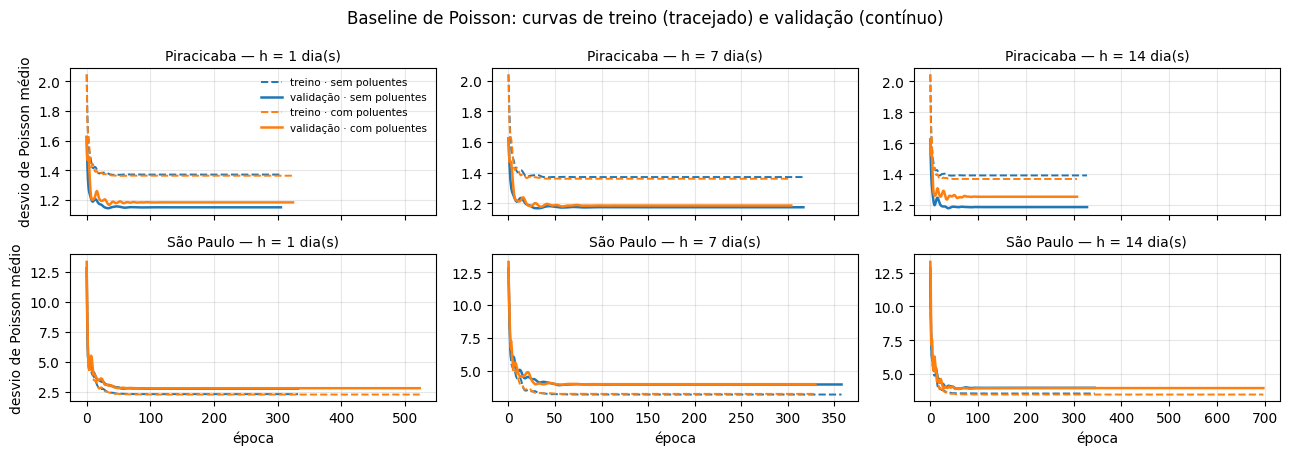

In [ ]:
# ---------------- Figura do M2: curvas de treino e validação ----------------
CORES = {ORDEM_MODELOS[1]: 'tab:blue', ORDEM_MODELOS[2]: 'tab:orange'}
fig, axes = plt.subplots(len(MUNICIPIOS), len(HORIZONTES), figsize=(13, 4.6), sharex='col', squeeze=False)
for i, m in enumerate(MUNICIPIOS):
    for j, h in enumerate(HORIZONTES):
        ax = axes[i, j]
        for nome in [ORDEM_MODELOS[1], ORDEM_MODELOS[2]]:
            c = curvas[(m, h, nome)]
            rotulo = nome.replace('Poisson ', '')
            ax.plot(c['treino'], color=CORES[nome], ls='--', lw=1.4, label=f'treino · {rotulo}')
            ax.plot(c['val'],    color=CORES[nome], ls='-',  lw=1.8, label=f'validação · {rotulo}')
        ax.set_title(f'{m} — h = {h} dia(s)', fontsize=10)
        ax.grid(alpha=.3)
        if j == 0:
            ax.set_ylabel('desvio de Poisson médio')
        if i == len(MUNICIPIOS) - 1:
            ax.set_xlabel('época')
axes[0, 0].legend(fontsize=7.5, frameon=False)
fig.suptitle('Baseline de Poisson: curvas de treino (tracejado) e validação (contínuo)', fontsize=12)
fig.tight_layout()
fig.savefig('fig_m2_curvas_poisson.png', dpi=200, bbox_inches='tight')
plt.show()

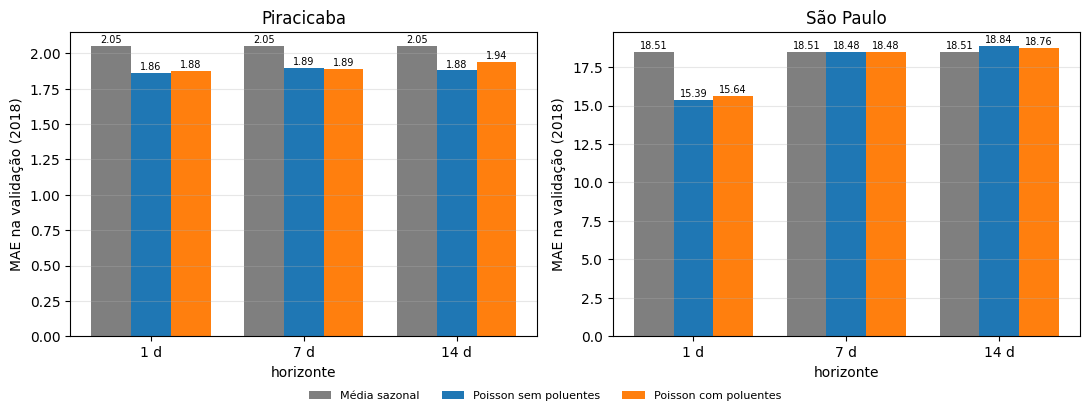

In [ ]:
# ---------------- Figura auxiliar: MAE de validação por modelo ----------------
fig, axes = plt.subplots(1, len(MUNICIPIOS), figsize=(11, 4.0))      # escalas diferentes: eixo y livre
largura = 0.26
CORES_BARRAS = ['tab:gray', 'tab:blue', 'tab:orange']
for ax, m in zip(np.atleast_1d(axes), MUNICIPIOS):
    for k, nome in enumerate(ORDEM_MODELOS):
        vals = [res[(res.municipio == m) & (res.horizonte == h) & (res.modelo == nome)]['MAE_val'].iloc[0] for h in HORIZONTES]
        pos = np.arange(len(HORIZONTES)) + (k - 1) * largura
        barras = ax.bar(pos, vals, largura, label=nome, color=CORES_BARRAS[k])
        ax.bar_label(barras, fmt='%.2f', fontsize=7, padding=1)
    ax.set_xticks(np.arange(len(HORIZONTES)))
    ax.set_xticklabels([f'{h} d' for h in HORIZONTES])
    ax.set_title(m); ax.set_xlabel('horizonte'); ax.set_ylabel('MAE na validação (2018)'); ax.grid(axis='y', alpha=.3)
h_, l_ = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(h_, l_, loc='lower center', ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout()
fig.savefig('fig_m2_mae_validacao.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# ---------------- Tempo de execução (para preencher o parágrafo da seção 5) ----------------
t_total = time.perf_counter() - T0
poi = res[res['modelo'] != ORDEM_MODELOS[0]]
print(f'Tempo total de execução (da leitura dos dados até aqui): {t_total:.1f} s — {AMBIENTE}')
print(f'Ajuste de um Poisson: mediana de {poi["tempo_ajuste_s"].median():.3f} s por configuração | '
      f'épocas até convergir: {int(poi["epocas"].min())} a {int(poi["epocas"].max())} '
      f'(mediana {int(poi["epocas"].median())}, {len(poi)} configurações)')
print('Arquivos gerados: fig_m2_curvas_poisson.png (Figura 1), fig_m2_mae_validacao.png, resultados_m2.csv')
if NO_COLAB:
    print('No Colab, baixe esses arquivos (painel Arquivos) ou copie-os para o Drive: a sessão é descartável.')

Tempo total de execução (da leitura dos dados até aqui): 8.0 s — Google Colab (CPU)
Ajuste de um Poisson: mediana de 0.052 s por configuração | épocas até convergir: 305 a 698 (mediana 330, 12 configurações)
Arquivos gerados: fig_m2_curvas_poisson.png (Figura 1), fig_m2_mae_validacao.png, resultados_m2.csv
No Colab, baixe esses arquivos (painel Arquivos) ou copie-os para o Drive: a sessão é descartável.


## 5. Parágrafo do M2
Medimos três baselines para prever as internações respiratórias diárias em Piracicaba (cerca de 5 por dia) e em São Paulo (cerca de 150 por dia), nos horizontes de 1, 7 e 14 dias: média sazonal com tendência e regressão de Poisson sem e com poluentes. Todos usam a mesma divisão (treino em 2014–2017, validação em 2018; o teste de 2019 não foi consultado), a mesma métrica (MAE) e o mesmo pré-processamento. Em 1 dia, o MAE de validação foi de 2,05, 1,86 e 1,88 em Piracicaba e de 18,51, 15,39 e 15,64 em São Paulo (40,1%, 36,4% e 36,8% da média diária em Piracicaba; 12,4%, 10,3% e 10,5% em São Paulo). Em 7 e 14 dias, os modelos de Poisson ficaram abaixo da média sazonal em Piracicaba e próximos dela em São Paulo. A diferença entre o Poisson com e sem poluentes teve sinal misto e é apenas descritiva, porque esses modelos não dependem de semente; a pergunta sobre os poluentes será respondida com o GRU no M3. Segundo a Figura 1, o treino converge em 305 a 698 épocas, e o notebook inteiro rodou em 8,0 s no Google Colab, em CPU.


***Observações sobre os dados**: poluentes e meteorologia são médias municipais entre as estações em operação em cada dia. Em Piracicaba (uma estação), temperatura e umidade ficaram sem medição válida em cerca de 66% e 80% dos dias de validação e foram preenchidas com o último valor ou com a média mensal do treino; São Paulo tem todas as variáveis medidas em 100% dos dias.

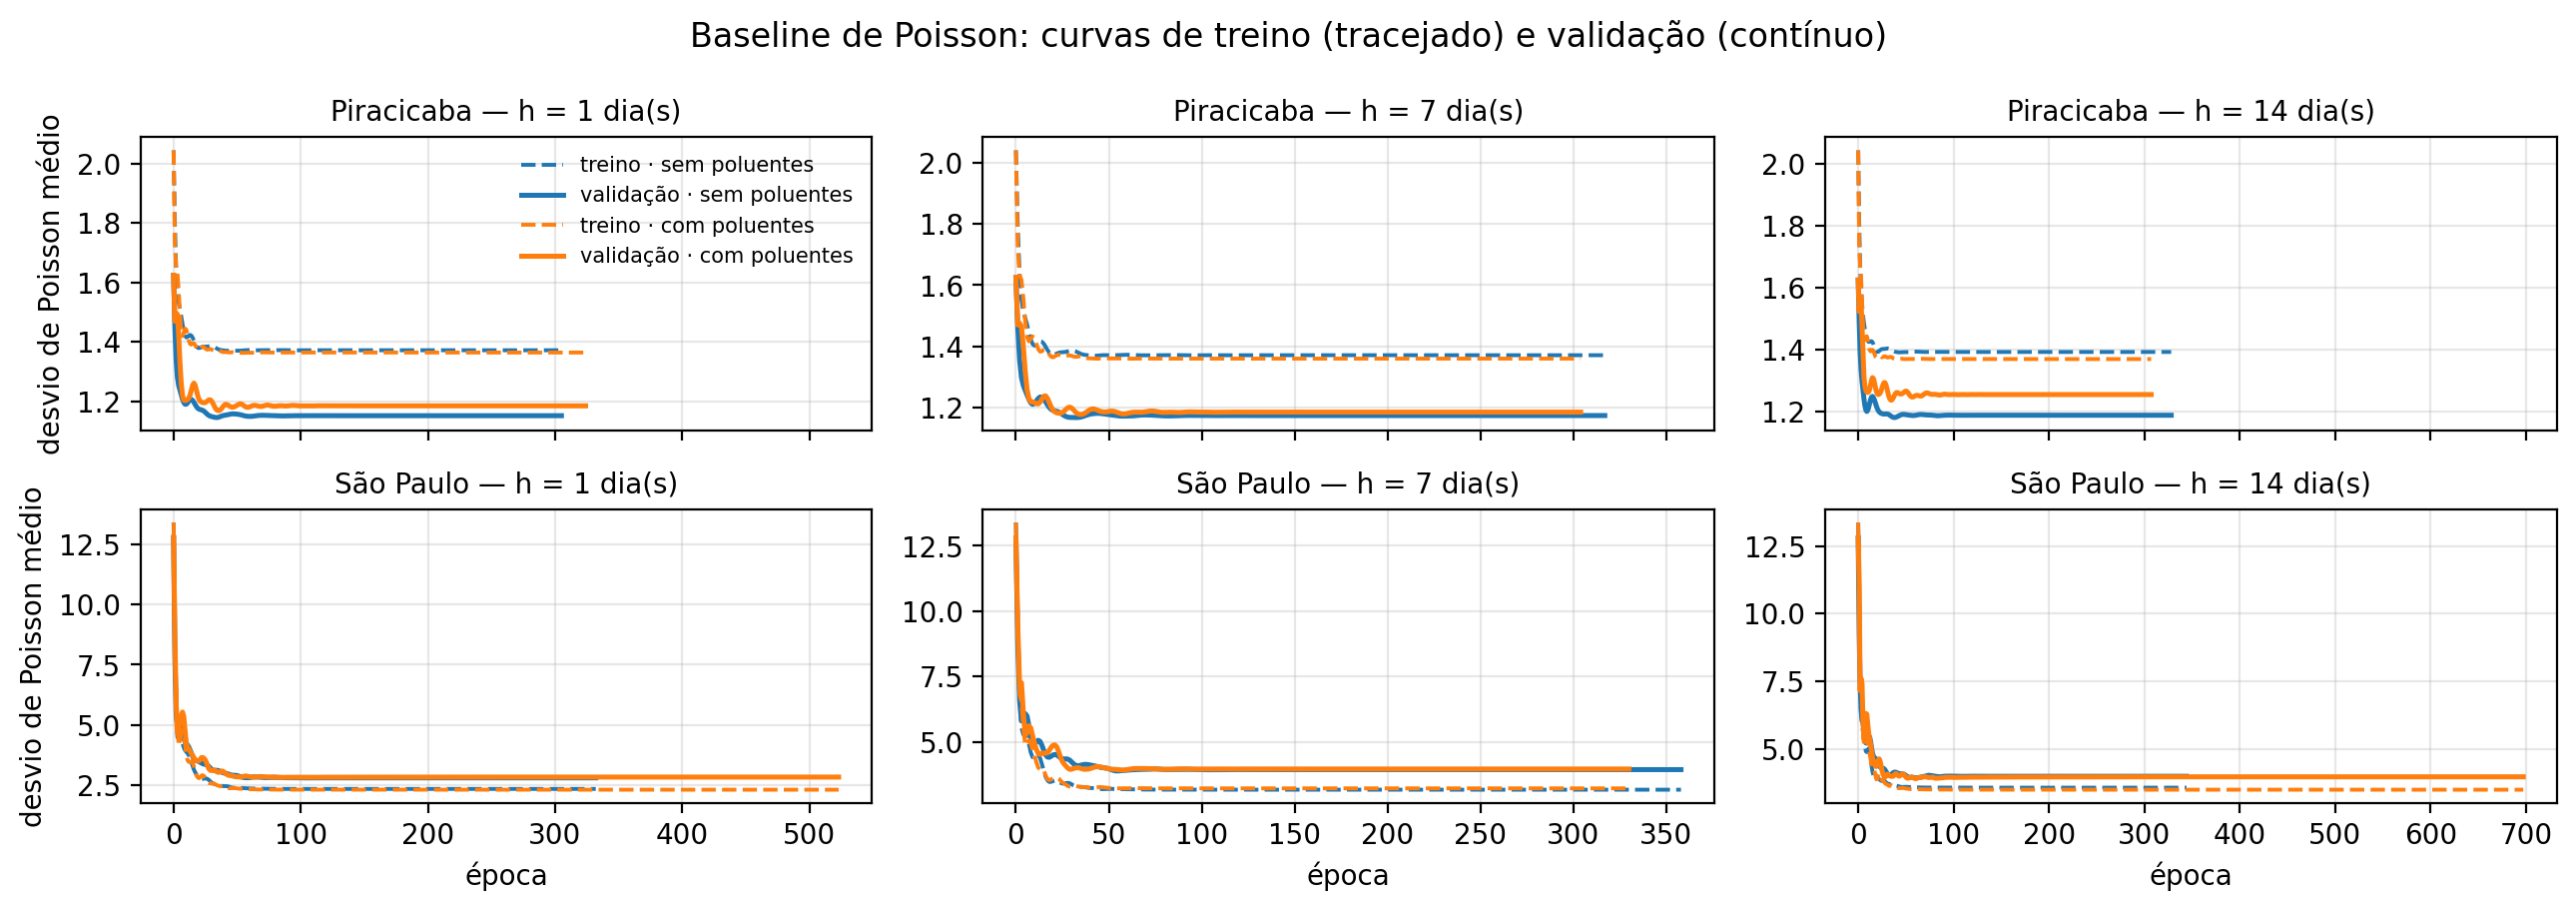

In [ ]:
# Figura 1 do M2 (gerada na seção 4)
import os
from IPython.display import Image, display

if os.path.exists('fig_m2_curvas_poisson.png'):
    display(Image('fig_m2_curvas_poisson.png'))
else:
    print('Arquivo não encontrado: execute antes a célula "Figura do M2" (seção 4).')